In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = "/kaggle/input/datasets/olistbr/brazilian-ecommerce/"
orders = pd.read_csv(path + "olist_orders_dataset.csv")
items = pd.read_csv(path + "olist_order_items_dataset.csv")
products = pd.read_csv(path + "olist_products_dataset.csv")
customers = pd.read_csv(path + "olist_customers_dataset.csv")
reviews = pd.read_csv(path + "olist_order_reviews_dataset.csv")
trans = pd.read_csv(path + "product_category_name_translation.csv")

In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
tables = {"orders": orders, "items": items, "products": products,
          "customers": customers, "reviews": reviews, "trans": trans}

for name, df in tables.items():
    print("=" * 40)
    print(name, "| rows, columns:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

orders | rows, columns: (99441, 8)
Duplicate rows: 0
Missing values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64
items | rows, columns: (112650, 7)
Duplicate rows: 0
Missing values:
Series([], dtype: int64)
products | rows, columns: (32951, 9)
Duplicate rows: 0
Missing values:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
customers | rows, columns: (99441, 5)
Duplicate rows: 0
Missing values:
Series([], dtype: int64)
reviews | rows, columns: (99224, 7)
Duplicate rows: 0
Missing values:
review_comment_title      87656
review_comment_message    58247
dtype: int64
trans | rows, columns: (71, 2)
Duplicate rows: 0
Missing values:
Series([], dtype: int64)


In [7]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


## Data Inspection Notes
- orders has 5 rows; missing values found in 3 columns;product has 8 columns,reviews has 2 columns
- products has missing category names (610 rows)
- Date columns are stored as text and need converting

## Data Inspection Notes

- orders: 99,441 rows, 8 columns. Missing values in 3 columns:
  order_approved_at (160), order_delivered_carrier_date (1,783),
  order_delivered_customer_date (2,965). These are mostly cancelled or
  undelivered orders.
- items: 112,650 rows, 7 columns. No missing values.
- products: 32,951 rows, 9 columns. Missing values in 8 columns. 610 rows have
  no category name (the same rows also lack name length, description length
  and photo count), and 2 rows lack weight and dimensions.
- customers: 99,441 rows, 5 columns. No missing values.
- reviews: 99,224 rows, 7 columns. Missing values in 2 columns:
  review_comment_title (87,656) and review_comment_message (58,247). These are
  optional text fields and are not needed for the analysis.
- trans: 71 rows, 2 columns. No missing values.
- No duplicate rows in any of the six tables.
- Date columns (e.g. order_purchase_timestamp) are stored as text (object type)
  and need converting to datetime.

In [8]:
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_carrier_date", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [9]:
print("Before:", len(orders))
print(orders["order_status"].value_counts())

orders = orders[orders["order_status"] == "delivered"]
print("After:", len(orders))

Before: 99441
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
After: 96478


In [10]:
products = products.merge(trans, on="product_category_name", how="left")
products["product_category_name_english"] = products["product_category_name_english"].fillna("unknown")

print(products["product_category_name_english"].isnull().sum())
print(products["product_category_name_english"].value_counts().head())

0
product_category_name_english
bed_bath_table     3029
sports_leisure     2867
furniture_decor    2657
health_beauty      2444
housewares         2335
Name: count, dtype: int64


In [12]:
print("Orders with more than one review:", reviews["order_id"].duplicated().sum())

reviews_clean = reviews.groupby("order_id")["review_score"].mean().reset_index()
print(len(reviews_clean))

Orders with more than one review: 551
98673


## Data Cleaning Decisions

1. Converted all 5 date columns in orders from text to datetime so we can
   group sales by month.
2. Kept only orders with status "delivered" (96,478 of 99,441). Cancelled and
   unavailable orders do not represent real revenue. This also removed most
   missing delivery dates.
3. Merged the product category translation file to get English category names.
4. Replaced 610 missing category names (plus a few untranslated ones) with
   "unknown" instead of dropping them, to keep their revenue in the totals.
5. Checked all six tables for duplicate rows: none found.
6. Reduced reviews to one average score per order (551 orders had multiple
   reviews; 98,673 unique reviewed orders remain), because merging them
   directly would duplicate rows.
7. Left blank review comment fields as they are, since the analysis only uses
   review scores.
8. Merged orders, items, products, customers and reviews into one table of
   110,197 item-level rows. Revenue is defined as item price (excluding
   freight). Total revenue is 13.22 million BRL.

In [13]:
df = (orders
      .merge(items, on="order_id")
      .merge(products[["product_id", "product_category_name_english"]], on="product_id")
      .merge(customers[["customer_id", "customer_state"]], on="customer_id")
      .merge(reviews_clean, on="order_id", how="left"))

df["revenue"] = df["price"]
df["month"] = df["order_purchase_timestamp"].dt.to_period("M")

print(df.shape)
print(df["revenue"].sum())
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()

(110197, 19)
13221498.110000001
order_approved_at                 15
order_delivered_carrier_date       2
order_delivered_customer_date      8
review_score                     827
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,customer_state,review_score,revenue,month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,SP,4.0,29.99,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,BA,4.0,118.70,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,GO,5.0,159.90,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,RN,5.0,45.00,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,stationery,SP,5.0,19.90,2018-02


In [14]:
region_map = {
 **dict.fromkeys(["AC","AP","AM","PA","RO","RR","TO"], "North"),
 **dict.fromkeys(["AL","BA","CE","MA","PB","PE","PI","RN","SE"], "Northeast"),
 **dict.fromkeys(["DF","GO","MT","MS"], "Central-West"),
 **dict.fromkeys(["ES","MG","RJ","SP"], "Southeast"),
 **dict.fromkeys(["PR","RS","SC"], "South")}
df["region"] = df["customer_state"].map(region_map)
print(df["region"].isnull().sum())

0


In [15]:
# Q1: Top categories by revenue
cat_rev = df.groupby("product_category_name_english")["revenue"].sum().sort_values(ascending=False)
print(cat_rev.head(10))

product_category_name_english
health_beauty            1233131.72
watches_gifts            1166176.98
bed_bath_table           1023434.76
sports_leisure            954852.55
computers_accessories     888724.61
furniture_decor           711927.69
housewares                615628.69
cool_stuff                610204.10
auto                      578966.65
toys                      471286.48
Name: revenue, dtype: float64


In [16]:
# Q2: Revenue by month
monthly = df.groupby("month")["revenue"].sum()
print(monthly)
print("Peak month:", monthly.idxmax(), monthly.max())

month
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: revenue, dtype: float64
Peak month: 2017-11 987765.37


In [17]:
# Q3: Revenue by region
region_rev = df.groupby("region")["revenue"].sum().sort_values(ascending=False)
print(region_rev)

region
Southeast       8648409.57
South           1901973.11
Northeast       1497083.78
Central-West     846956.70
North            327074.95
Name: revenue, dtype: float64


In [18]:
# Q4: Average order value by month
order_totals = df.groupby(["order_id", "month"])["revenue"].sum().reset_index()
aov = order_totals.groupby("month")["revenue"].mean()
print(aov)

month
2016-09    134.970000
2016-10    152.170226
2016-12     10.900000
2017-01    149.064480
2017-02    141.695947
2017-03    141.083602
2017-04    147.924307
2017-05    137.997250
2017-06    134.584807
2017-07    124.381333
2017-08    132.291844
2017-09    146.361366
2017-10    144.762762
2017-11    135.514525
2017-12    131.694756
2018-01    130.802801
2018-02    126.077365
2018-03    136.135406
2018-04    143.208898
2018-05    144.842894
2018-06    140.363643
2018-07    140.924413
2018-08    132.038520
Freq: M, Name: revenue, dtype: float64


In [19]:
# Q5: Review score distribution
score_dist = df.drop_duplicates("order_id")["review_score"].round().value_counts().sort_index()
print(score_dist)

review_score
1.0     9313
2.0     2954
3.0     7916
4.0    18945
5.0    56704
Name: count, dtype: int64


## Sales Analysis Answers

1. Top category by revenue: health_beauty (1.23M BRL, 9.3% of total).
2. Peak sales month: November 2017 (987,765 BRL).
3. Best region: Southeast (8.65M BRL, 65% of total revenue).
4. Average order value stayed between about 125 and 150 BRL from 2017 to 2018.
5. Review scores: 59% of orders scored 5 stars, 20% scored 4 stars, and
   about 10% scored 1 star.

Note: 2016 months have very little data (dataset starts in Sept 2016 with
gaps), so trend charts start from January 2017.

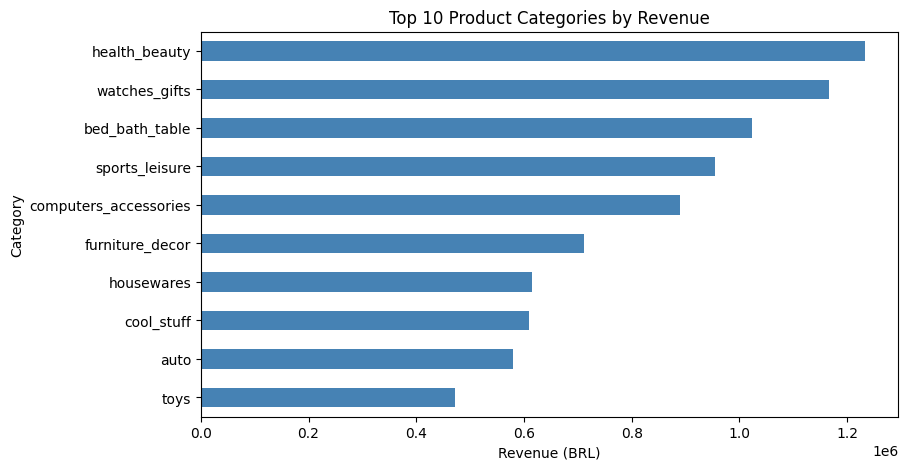

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

cat_rev.head(10).sort_values().plot(kind="barh", figsize=(9,5), color="steelblue")
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Category")
plt.show()

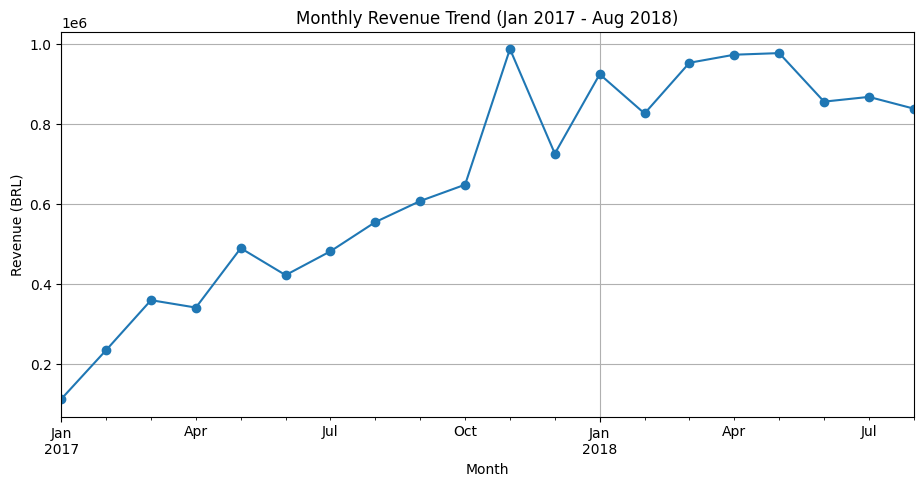

In [21]:
monthly_trim = monthly["2017-01":"2018-08"]
monthly_trim.plot(figsize=(11,5), marker="o")
plt.title("Monthly Revenue Trend (Jan 2017 - Aug 2018)")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.grid(True)
plt.show()

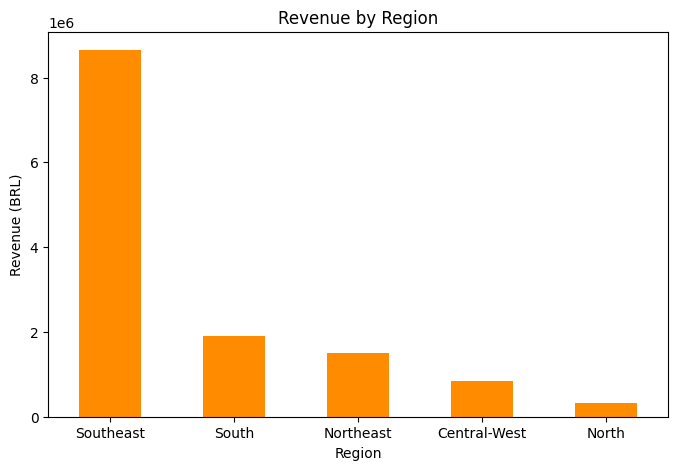

In [22]:
region_rev.plot(kind="bar", figsize=(8,5), color="darkorange")
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=0)
plt.show()

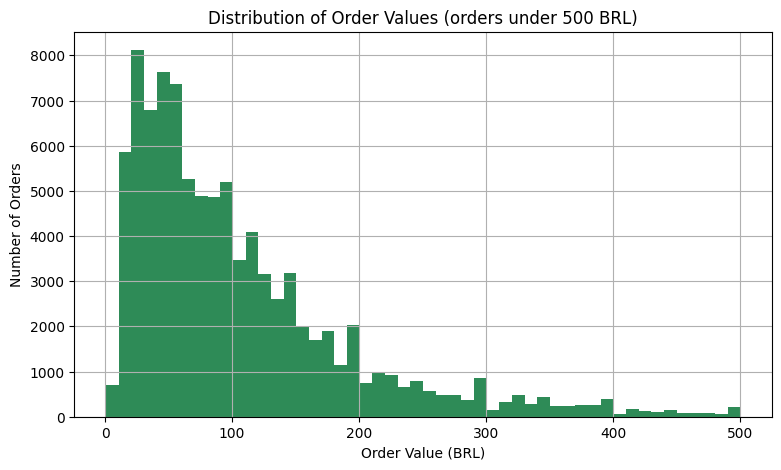

In [23]:
vals = order_totals["revenue"]
vals[vals < 500].hist(bins=50, figsize=(9,5), color="seagreen")
plt.title("Distribution of Order Values (orders under 500 BRL)")
plt.xlabel("Order Value (BRL)")
plt.ylabel("Number of Orders")
plt.show()

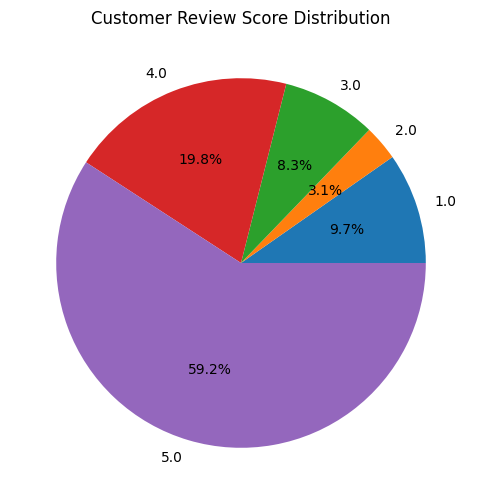

In [24]:
score_dist.plot(kind="pie", autopct="%1.1f%%", figsize=(6,6))
plt.title("Customer Review Score Distribution")
plt.ylabel("")
plt.show()

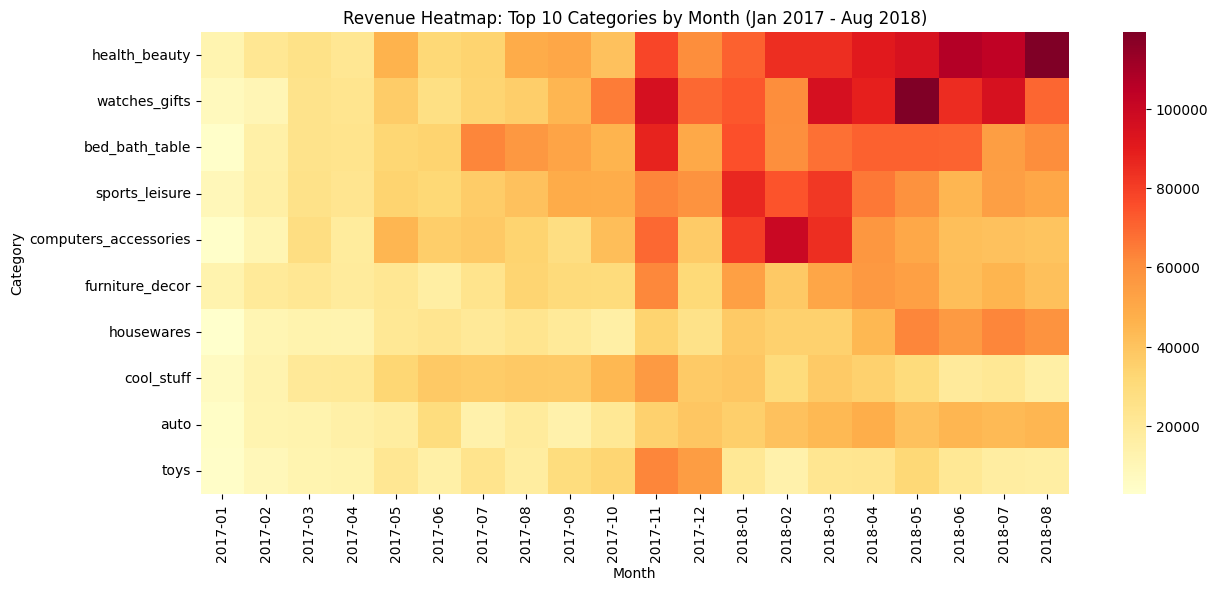

In [26]:
pivot = df.pivot_table(index="product_category_name_english",
                       columns="month", values="revenue", aggfunc="sum")
pivot = pivot.loc[cat_rev.head(10).index].fillna(0)
pivot.columns = pivot.columns.astype(str)
pivot = pivot.loc[:, pivot.columns >= "2017-01"]

plt.figure(figsize=(14,6))
sns.heatmap(pivot, cmap="YlOrRd")
plt.title("Revenue Heatmap: Top 10 Categories by Month (Jan 2017 - Aug 2018)")
plt.xlabel("Month")
plt.ylabel("Category")
plt.show()

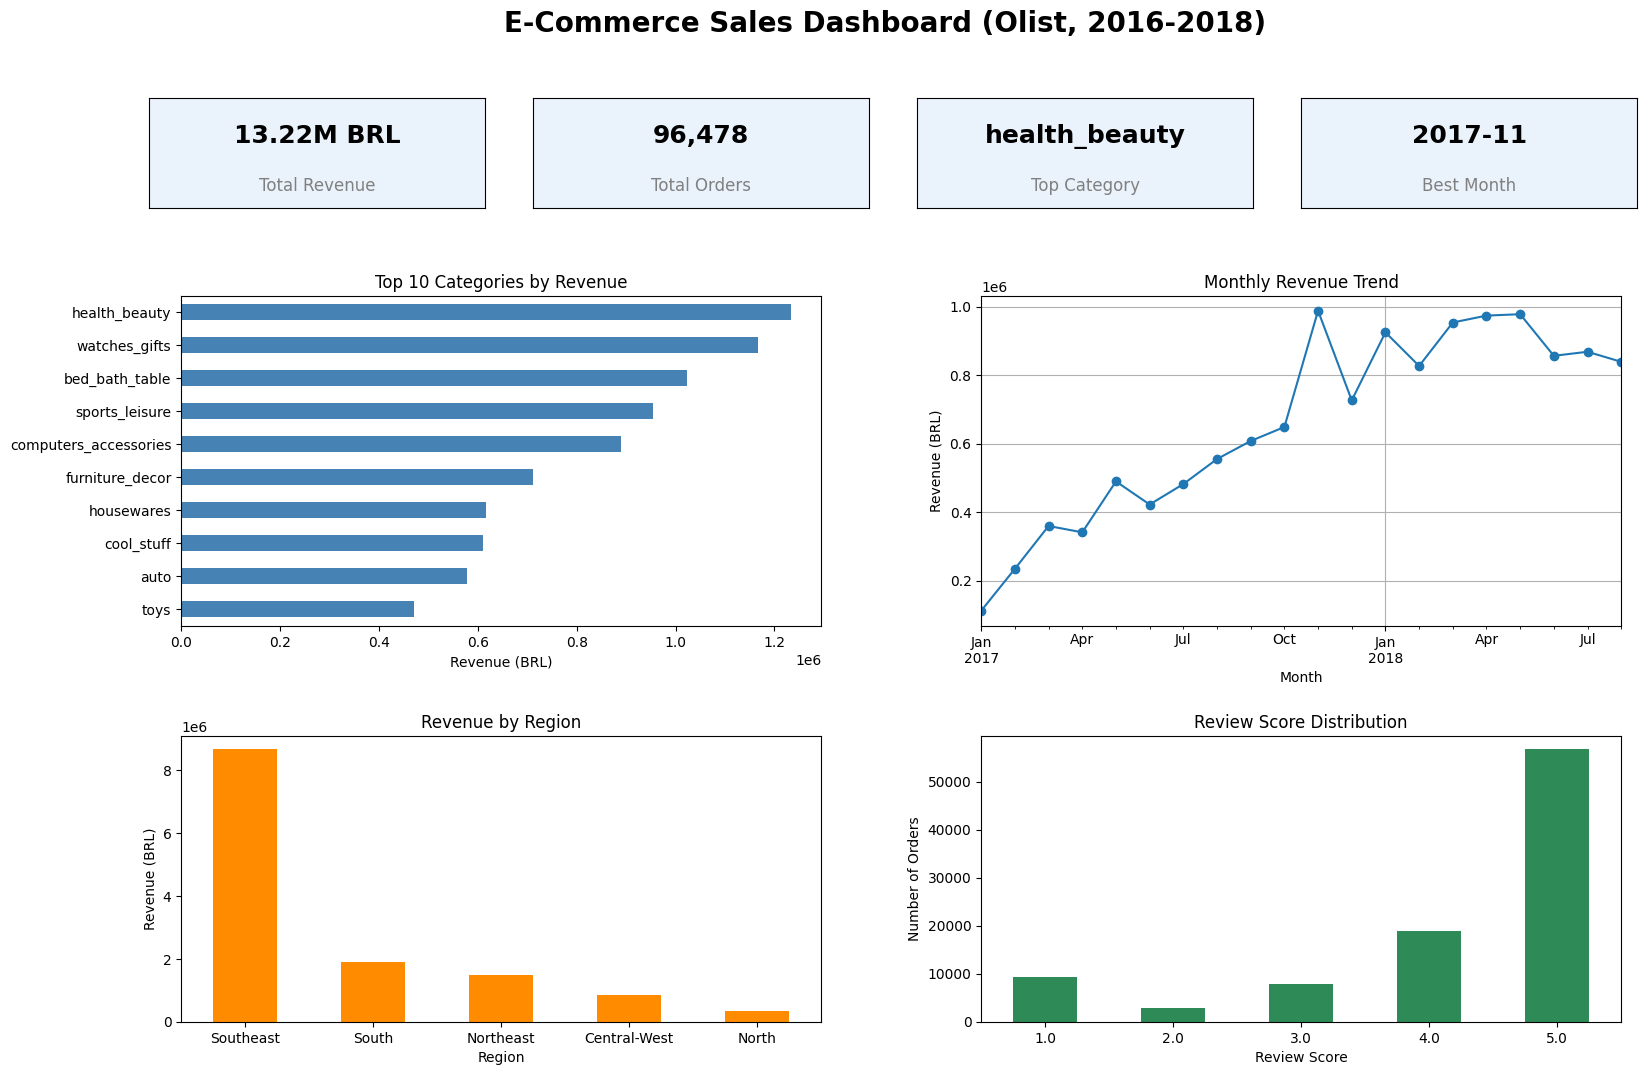

In [28]:
total_revenue = df["revenue"].sum()
total_orders = df["order_id"].nunique()
top_category = cat_rev.idxmax()
best_month = str(monthly.idxmax())

fig = plt.figure(figsize=(16, 11))
fig.suptitle("E-Commerce Sales Dashboard (Olist, 2016-2018)", fontsize=20, fontweight="bold")

# KPI boxes
kpis = [("Total Revenue", f"{total_revenue/1e6:.2f}M BRL"),
        ("Total Orders", f"{total_orders:,}"),
        ("Top Category", top_category),
        ("Best Month", best_month)]
for i, (label, value) in enumerate(kpis):
    ax = fig.add_axes([0.04 + i*0.24, 0.80, 0.21, 0.10])
    ax.set_facecolor("#eaf2fb")
    ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.5, 0.65, value, ha="center", va="center", fontsize=18, fontweight="bold")
    ax.text(0.5, 0.2, label, ha="center", va="center", fontsize=12, color="gray")

# Charts
ax1 = fig.add_axes([0.06, 0.42, 0.40, 0.30])
cat_rev.head(10).sort_values().plot(kind="barh", ax=ax1, color="steelblue")
ax1.set_title("Top 10 Categories by Revenue")
ax1.set_xlabel("Revenue (BRL)"); ax1.set_ylabel("")

ax2 = fig.add_axes([0.56, 0.42, 0.40, 0.30])
monthly["2017-01":"2018-08"].plot(ax=ax2, marker="o")
ax2.set_title("Monthly Revenue Trend")
ax2.set_xlabel("Month"); ax2.set_ylabel("Revenue (BRL)"); ax2.grid(True)

ax3 = fig.add_axes([0.06, 0.06, 0.40, 0.26])
region_rev.plot(kind="bar", ax=ax3, color="darkorange")
ax3.set_title("Revenue by Region")
ax3.set_xlabel("Region"); ax3.set_ylabel("Revenue (BRL)")
ax3.tick_params(axis="x", rotation=0)

ax4 = fig.add_axes([0.56, 0.06, 0.40, 0.26])
score_dist.plot(kind="bar", ax=ax4, color="seagreen")
ax4.set_title("Review Score Distribution")
ax4.set_xlabel("Review Score"); ax4.set_ylabel("Number of Orders")
ax4.tick_params(axis="x", rotation=0)

plt.savefig("dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

### Business Insights Report (Simple Words)

Insight 1: Health and beauty products generate the most revenue.

Health and beauty products earned ₹1.23 million BRL, followed by watches and gifts at ₹1.17 million and bed and bath products at ₹1.02 million. Together, these three categories contribute about 26% of total revenue (Chart 1).

Recommendation: Keep enough stock of these products and spend more on their marketing to increase sales.

Insight 2: Sales were highest in November 2017.

The business earned ₹987,765 BRL in November 2017, the highest monthly revenue. Sales increased across almost all product categories during this month (Charts 2 and 6).

Recommendation: Prepare extra stock, staff, and special offers before November to take advantage of Black Friday sales.

Insight 3: Most sales come from the Southeast region.

The Southeast region generates ₹8.65 million BRL, around 65% of total revenue. In comparison, the North region generates only ₹0.33 million BRL (Chart 3).

Recommendation: Focus on increasing sales in the South and Northeast regions to reach more customers and reduce dependence on the Southeast.

Insight 4: The average amount spent per order is not increasing.

The average order value stays around ₹125–₹150 BRL, and most customers spend less than ₹100 BRL per order (Chart 4).

Recommendation: Encourage customers to buy more products through product bundles, discounts on larger orders, and free shipping above a certain amount.

Insight 5: Customers are mostly satisfied, but 1-star reviews outnumber 2-star.

Around 79% of orders are rated 4 or 5 stars, but 9.7% are 1 star, which is more than three times  the 2-star share of 3.1% (Chart 5).

Recommendation: investigate 1-star orders for delivery delays or product problems and fix the root cause .

## Most Surprising Finding

Revenue growth came from selling more orders, not bigger ones : average order value stayed flat at about 125-150 BRL while monthly revenue grew almost 9x between jan 2017(about 112k BRL) and nov 2017(about 988k BRL) . Also, one region (Southeast) produces 65% of all revenue, so the business is far more concentrated than the category data suggests. 